In [14]:
from langgraph.graph import StateGraph, START, END
from typing import List, Dict, Optional, Annotated, Literal
from langchain_core.messages import HumanMessage, BaseMessage
from langgraph.checkpoint.memory import MemorySaver
from langgraph.graph.message import add_messages

from langchain_community.document_loaders import PyPDFLoader
from langchain_text_splitters import RecursiveCharacterTextSplitter

from langchain_groq import ChatGroq
from langchain_google_genai import ChatGoogleGenerativeAI
from langchain_ollama import OllamaEmbeddings
from langchain_google_genai import GoogleGenerativeAIEmbeddings
from langchain_community.vectorstores import FAISS

from langchain_core.tools import tool
from langgraph.prebuilt import ToolNode, tools_condition
from pydantic import BaseModel, Field
from dotenv import load_dotenv
import operator

load_dotenv()

True

In [3]:
llm = ChatGroq(model="openai/gpt-oss-20b")

In [4]:
loader = PyPDFLoader("my_paper.pdf")
docs = loader.load()

Multiple definitions in dictionary at byte 0x6778 for key /Group
Multiple definitions in dictionary at byte 0x987e7 for key /Group
Multiple definitions in dictionary at byte 0xbb622 for key /Group
Multiple definitions in dictionary at byte 0x145ac9 for key /Group
Multiple definitions in dictionary at byte 0x15e634 for key /Group
Multiple definitions in dictionary at byte 0x1807c9 for key /Group


In [5]:
docs

[Document(metadata={'producer': 'pdfTeX-1.40.29', 'creator': 'LaTeX with hyperref', 'creationdate': '2026-06-09T15:52:04+02:00', 'author': '', 'title': '', 'subject': '', 'keywords': '', 'moddate': '2026-06-09T15:52:04+02:00', 'trapped': '/False', 'ptex.fullbanner': 'This is pdfTeX, Version 3.141592653-2.6-1.40.29 (TeX Live 2026) kpathsea version 6.4.2', 'source': 'my_paper.pdf', 'total_pages': 24, 'page': 0, 'page_label': '323'}, page_content='Proceedings of the 64th Annual Meeting of the Association for Computational Linguistics (V olume 1: Long Papers), pages 323–346\nJuly 2-7, 2026 ©2026 Association for Computational Linguistics\nParallel Universes, Parallel Languages: A Comprehensive Study on\nLLM-based Multilingual Counterfactual Example Generation\nQianli Wang1,2,†\nVan Bach Nguyen3 Yihong Liu4,5 Fedor Splitt1 Nils Feldhus1,2,6\nChristin Seifert3 Hinrich Schütze4,5 Sebastian Möller1,2 Vera Schmitt1,2\n1Technische Universität Berlin 2German Research Center for Artificial Intellig

In [6]:
len(docs)

24

In [7]:
splitter = RecursiveCharacterTextSplitter(chunk_size = 1000, chunk_overlap = 200)
chunks = splitter.split_documents(docs)

In [8]:
len(chunks)

118

In [9]:
embeddings = OllamaEmbeddings(model="nomic-embed-text")

vector_store = FAISS.from_documents(chunks, embeddings)
vector_store.save_local("faiss_index")

In [10]:
# search type similarity and kwargs 4 means 4 ta relevant results niye ashbe. 4 relevant chunks niye ashbe
retriever = vector_store.as_retriever(search_type = 'similarity', search_kwargs = {'k':4})

In [11]:
@tool
def rag_tool(query: str) -> str:
    """
    Retrieve relevant information from the PDF document.

    Use this tool when the user asks factual or conceptual questions
    that may be answered using the stored PDF documents.

    Args:
        query: The question or search query used to retrieve PDF content.
    """

    documents = retriever.invoke(query)

    if not documents:
        return "No relevant information was found in the PDF."

    formatted_documents = []

    for index, document in enumerate(documents, start=1):
        source = document.metadata.get("source", "Unknown source")
        page = document.metadata.get("page", "Unknown page")

        formatted_documents.append(
            f"Document {index}\n"
            f"Source: {source}\n"
            f"Page: {page}\n"
            f"Content: {document.page_content}"
        )

    return "\n\n".join(formatted_documents)

In [12]:
tools = [rag_tool]
llm_with_tools = llm.bind_tools(tools=tools)

In [15]:
class ChatState(BaseModel):
    messages: Annotated[list[BaseMessage], add_messages]

In [16]:
def chat_node(state: ChatState):
    """LLM node that may answer or request a tool call."""
    messages = state.messages
    response = llm_with_tools.invoke(messages)
    return {
        "messages": [response]
        }

tool_node = ToolNode(tools)

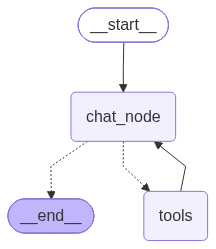

In [17]:
graph = StateGraph(ChatState)
graph.add_node("chat_node", chat_node)
graph.add_node("tools", tool_node)
graph.add_edge(START, "chat_node")

# If the LLM asked for a tool, go to ToolNode; else finish
graph.add_conditional_edges("chat_node", tools_condition)

graph.add_edge("tools", "chat_node")  
chatbot = graph.compile()

chatbot

In [18]:
result = chatbot.invoke({"messages": [HumanMessage(content="Hello")]})

print(result["messages"][-1].content)

Hello! 👋 How can I help you today?


In [22]:
result = chatbot.invoke({"messages": [HumanMessage(content="Using the pdf notes, explain about the methodology they used")]})

print(result["messages"][-1].content)

**Methodology Overview**  
The authors set out to study how large language models (LLMs) can generate *counterfactual* examples in multiple languages and how to assess the quality of those examples. Their approach is organized into three main stages:

| Stage | What was done | Key details from the PDF |
|-------|---------------|--------------------------|
| **1. Data & Pre‑processing** | • Two benchmark corpora were used: **XNLI** (cross‑lingual natural language inference) and **SIB200** (a multilingual sentiment‑analysis set). <br>• The authors first collected the *label‑flip* pairs (e.g., “neutral → entailment”) that the LLM would try to generate. <br>• They also examined the **label distribution** of each dataset (Fig. 10) to ensure balanced sampling. | *Page 17 – Fig. 10: Label distributions of XNLI and SIB200* |
| **2. Counterfactual Generation** | • The core idea is to prompt an LLM to *alter the predicted label* of an input sentence while preserving its meaning. <br>• Two genera